# 2026.10.13(화) 19h~

In [1]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Embedding, Flatten, LSTM
from sklearn.datasets import fetch_20newsgroups
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelBinarizer

newsgroups_data = fetch_20newsgroups(subset='all')
texts = newsgroups_data.data
labels = newsgroups_data.target

print(f"texts.shape = {len(texts)}, labels.shape = {len(labels)}")
print(f"texts[0] = {texts[0]}")
print(f"labels[0] = {labels[0]}")

2026-10-13 19:34:23.162115: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


texts.shape = 18846, labels.shape = 18846
texts[0] = From: Mamatha Devineni Ratnam <mr47+@andrew.cmu.edu>
Subject: Pens fans reactions
Organization: Post Office, Carnegie Mellon, Pittsburgh, PA
Lines: 12
NNTP-Posting-Host: po4.andrew.cmu.edu



I am sure some bashers of Pens fans are pretty confused about the lack
of any kind of posts about the recent Pens massacre of the Devils. Actually,
I am  bit puzzled too and a bit relieved. However, I am going to put an end
to non-PIttsburghers' relief with a bit of praise for the Pens. Man, they
are killing those Devils worse than I thought. Jagr just showed you why
he is much better than his regular season stats. He is also a lot
fo fun to watch in the playoffs. Bowman should let JAgr have a lot of
fun in the next couple of games since the Pens are going to beat the pulp out of Jersey anyway. I was very disappointed not to see the Islanders lose the final
regular season game.          PENS RULE!!!


labels[0] = 10


In [2]:
tokenizer = Tokenizer(num_words=20000)
tokenizer.fit_on_texts(texts)
sequences = tokenizer.texts_to_sequences(texts)
word_index = tokenizer.word_index

print(f"sequences[0] = {sequences[0]}")
print(f"len(sequences) = {len(sequences[0])}")

print(f"word_index = {word_index}")
print(f"len(word_index) = {len(word_index)}")

sequences[0] = [14, 19415, 455, 559, 15, 29, 2552, 1240, 5609, 33, 322, 767, 2175, 2121, 871, 1343, 32, 251, 88, 77, 84, 12087, 455, 559, 15, 7, 122, 228, 63, 3, 2552, 1240, 20, 517, 3490, 50, 1, 1393, 3, 61, 437, 3, 1507, 50, 1, 1302, 2552, 3027, 3, 1, 2701, 309, 7, 122, 243, 16334, 175, 5, 4, 243, 19416, 268, 7, 122, 194, 2, 296, 37, 337, 2, 369, 4389, 22, 4, 243, 3, 7286, 12, 1, 2552, 349, 30, 20, 1502, 137, 2701, 1382, 90, 7, 397, 5987, 74, 2025, 13, 130, 56, 8, 140, 215, 90, 93, 1457, 770, 1963, 56, 8, 97, 4, 308, 9186, 1857, 2, 1306, 6, 1, 2327, 6760, 115, 348, 5987, 21, 4, 308, 3, 1857, 6, 1, 365, 658, 3, 467, 185, 1, 2552, 20, 194, 2, 1985, 1, 66, 3, 3215, 608, 7, 26, 132, 8755, 19, 2, 131, 1, 3280, 2000, 1, 1151, 1457, 770, 283, 2552, 1222]
len(sequences) = 160
word_index = {'the': 1, 'to': 2, 'of': 3, 'a': 4, 'and': 5, 'in': 6, 'i': 7, 'is': 8, 'that': 9, "'ax": 10, 'it': 11, 'for': 12, 'you': 13, 'from': 14, 'edu': 15, 'on': 16, 'this': 17, 'be': 18, 'not': 19, 'are': 20, 'h

In [3]:
max_len = 1000

data = pad_sequences(sequences, maxlen=max_len)
labels = LabelBinarizer().fit_transform(labels)

x_train, x_test, y_train, y_test = train_test_split(data, labels, test_size=0.2, random_state=0)

[[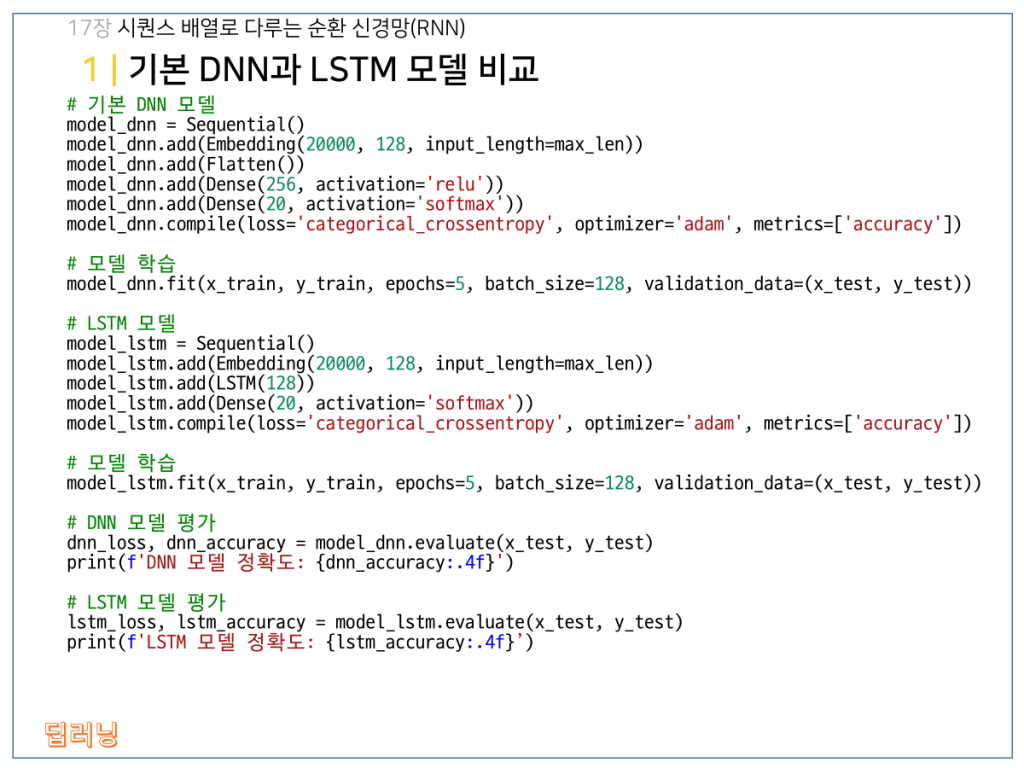](https://media.discordapp.net/attachments/1547059108019179540/1559507381250035832/image.png?ex=6acf53ed&is=6ace026d&hm=6b02d7de2b49806ba05e0978b51bdcf318a92f88d4031f3e439a279c2d19bec3&=&format=webp&quality=lossless&width=1024&height=768)]

In [4]:
model_dnn = Sequential()
model_dnn.add(Embedding(20000, 128, input_length=max_len))
model_dnn.add(Flatten()) # 다차원 배열을 1차원으로 펼치
model_dnn.add(Dense(256, activation='relu')) # hidden layer의 비선형성 관리를 위한 층 하나 추가
model_dnn.add(Dense(20, activation='softmax'))
model_dnn.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

model_dnn.fit(x_train, y_train, epochs=5, batch_size=128, validation_data=(x_test, y_test))

/opt/anaconda3/envs/voice-ai/lib/python3.11/site-packages/keras/src/layers/core/embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/5
118/118 ━━━━━━━━━━━━━━━━━━━━ 230s 2s/step - accuracy: 0.0623 - loss: 4.3072 - val_accuracy: 0.0716 - val_loss: 2.9402
Epoch 2/5
118/118 ━━━━━━━━━━━━━━━━━━━━ 222s 2s/step - accuracy: 0.1071 - loss: 2.8423 - val_accuracy: 0.1236 - val_loss: 2.7178
Epoch 3/5
118/118 ━━━━━━━━━━━━━━━━━━━━ 173s 1s/step - accuracy: 0.2375 - loss: 3.1247 - val_accuracy: 0.1419 - val_loss: 2.7412
Epoch 4/5
118/118 ━━━━━━━━━━━━━━━━━━━━ 136s 1s/step - accuracy: 0.1272 - loss: 2.6362 - val_accuracy: 0.1029 - val_loss: 2.7228
Epoch 5/5
118/118 ━━━━━━━━━━━━━━━━━━━━ 97s 817ms/step - accuracy: 0.1839 - loss: 2.4820 - val_accuracy: 0.1533 - val_loss: 2.5066


In [ ]:
# lstm 은닉 상태 128개 = 출력이 1차원
# 단어의 

# 2026.10.13(화) 20h~ LSTM 정리_self quiz

1. 
- [forget gate] 정보 제거: Forget Gate가 이전 Cell State에서 계속 유지할 정보와 제거할 정보의 비율을 결정한다.
- [input gate] 새로운 정보 선택: Input Gate가 현재 입력으로부터 새롭게 기억할 정보를 선택한다.
- [cell state] Cell State 갱신: 기존 기억 중 유지할 정보와 새롭게 선택한 정보를 결합해 현재 Cell State를 만든다(장기 기억을 전달하는 통로)
- [output gate] 출력 생성: Output Gate(저장된 정보 중 무엇을 출력할지 결정)가 갱신된 Cell State를 바탕으로 현재 Hidden State를 생성한다.
- [hidden state] 다음 시점으로 전달: 현재의 Cell State와 Hidden State(현재 시점의 정보를 반영한 출력)를 다음 시점으로 전달하여 이후 데이터 처리에 활용한다.

2. LSTM이 순차 데이터를 처리할 때 cell state에서 forget gate를 거치며 일부를 유지하거나 잊음으로써 이전 시점의 정보를 활용한다. input gate를 통해 필요한 정보를 기억하거나 제거하며 hidden state에 담아 다음 시점으로 전달한다.

3. LSTM 모델의 구성과 역할
- Embedding 층: 텍스트의 각 단어를 정수 인덱스로 표현한 입력을 받아, 각 단어를 저차원의 실수 벡터로 변환한다. 이를 통해 모델이 단어의 의미적 특성을 학습할 수 있도록 한다.
- LSTM 층: Embedding 층에서 생성된 단어 벡터를 순서대로 처리한다. 이전 시점의 정보를 활용해 문맥과 단어 사이의 순차적 관계를 학습하고, 텍스트 전체의 특징을 나타내는 은닉 표현을 생성한다. 일반적으로 마지막 Hidden State를 사용하거나, 설정에 따라 모든 시점의 출력을 다음 층으로 전달할 수 있다.
- Dense 층: LSTM이 추출한 특징을 바탕으로 최종 분류 결과를 계산한다. 이진 분류에서는 시그모이드 함수를 이용해 한 클래스에 속할 확률을 출력할 수 있으며, 다중 클래스 분류에서는 소프트맥스 함수를 이용해 각 클래스의 확률을 출력할 수 있다.